Optimization Complete.
Best Value Found: 2018
Total Weight Used: 207 / 207


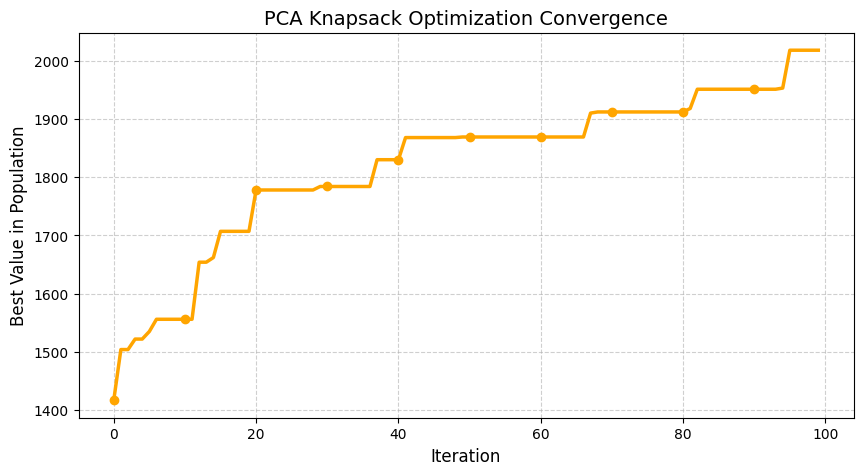

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

num_items = 50
weights = np.random.randint(1, 15, size=num_items)
values = np.random.randint(10, 100, size=num_items)
knapsack_capacity = int(0.5 * np.sum(weights))

def evaluate_knapsack(solution):
    total_weight = np.sum(solution * weights)
    if total_weight > knapsack_capacity:
        return 0
    return np.sum(solution * values)

num_cells = 20
max_iterations = 100
crossover_rate = 0.8
mutation_rate = 0.05

cells = np.random.randint(0, 2, size=(num_cells, num_items))
fitness = np.array([evaluate_knapsack(cell) for cell in cells])

history = []

for iteration in range(max_iterations):
    new_cells = np.copy(cells)

    for i in range(num_cells):
        neighbors_indices = [(i - 1) % num_cells, i, (i + 1) % num_cells]
        best_neighbor_idx = neighbors_indices[np.argmax(fitness[neighbors_indices])]
        best_neighbor = cells[best_neighbor_idx]

        candidate = np.copy(cells[i])
        if np.random.rand() < crossover_rate:
            cut_point = np.random.randint(1, num_items)
            candidate[cut_point:] = best_neighbor[cut_point:]

        mutation_mask = np.random.rand(num_items) < mutation_rate
        candidate[mutation_mask] = 1 - candidate[mutation_mask]

        candidate_fitness = evaluate_knapsack(candidate)
        if candidate_fitness > fitness[i]:
            new_cells[i] = candidate

    cells = new_cells
    fitness = np.array([evaluate_knapsack(cell) for cell in cells])
    history.append(np.max(fitness))

best_idx = np.argmax(fitness)
best_solution = cells[best_idx]
best_val = fitness[best_idx]
best_weight = np.sum(best_solution * weights)

print(f"Optimization Complete.")
print(f"Best Value Found: {best_val}")
print(f"Total Weight Used: {best_weight} / {knapsack_capacity}")

plt.figure(figsize=(10, 5))
plt.plot(history, color='orange', linewidth=2.5, marker='o', markevery=10)
plt.title("PCA Knapsack Optimization Convergence", fontsize=14)
plt.xlabel("Iteration", fontsize=12)
plt.ylabel("Best Value in Population", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()